# F16–F20: pCOBI scale, energy grid, |projection|² files, self-images, runs without smearing (implemented)

| finding | what | checked here with |
|---|---|---|
| F16 | integrated pCOBI was half the Wiberg/Mayer bond index | N2 no-spin, N2 z-spin and a graphene C–C bond: legacy vs. fixed vs. a float64 bond index (`fixcompare.Reference`) |
| F17 | default grid step (10 mHa) was 4.5 standard deviations of the default Gaussian; pad of only 10 `res` | one peak's area on the grid; N2 DOS and pCOHP on the old and new default grids; DOS integrals vs. `res` |
| F18 | `|projection|^2` bandProjections were used as projections: squared again, Löwdin-orthonormalized, and pair spectra returned numbers | a $\|T\|^2$ file built from `N2_nospin`: pDOS as the old code computed it, now, and from the complex file |
| F19 | an atom's interaction with its own periodic images was unreachable, and the kernel left out $\mu=\nu$ | graphene C #1 with its six second-neighbour images: crawfish vs. float64, and the $\mu=\nu$ share |
| F20 | pair spectra raised for calculations without smearing (no $\mu_F$) | `N2_nospin` with its $\mu_F$ removed, and `Si_nosmear_nospin` |

F16 has a legacy switch, `legacy_cobi_scale` (`fixcompare.LEGACY_FLAGS["F16"]`). F17 changed a default argument:
`res=0.01` gives the old grid, and the old spectra, exactly. F18–F20 are bug fixes or a new capability without a
switch (notes section 4.0); their "before" is rebuilt from what the old code computed, with the functions it called,
or quoted from the re-check of 2026-11-10. F15 changed only a warning (last section). Each section starts with what
crawfish did before, what was wrong with it, what changed and what it does now, and a table pointing each issue to a
figure. Figures are saved to `figures/` with an `F16_`…`F20_` prefix. The last cell holds the tests.

Notation as in the README: $T_{\mu,j}(t)=\langle\phi_\mu|\hat O|\psi_j(t)\rangle$ (`proj_tju`), $\epsilon_j(t)$
(`e_tj`), $f_j(t)\in[0,1]$ (`occ_tj`), $w_t$ (`wk_t`, summing to 2), $C_{\mu,j}(t)$ the coefficients (`coef_tju`),
$\mu_F$ the Fermi level (`edata.mu`), and $s=\sqrt{\sigma/2}$ the standard deviation of the Gaussian of width
parameter `sig` $=\sigma$. Pair spectra are $\sum_{j,t}w_t\,\mathrm{Re}[C^*_{\mu,j}M_{\mu\nu}C_{\nu,j}]\,\delta(E-\epsilon_j(t))$,
with $M_{\mu\nu}\to M_{\mu\nu}(R)\,e^{2\pi ik_t\cdot R}$ for the image of the second atom at lattice vector $R$.

In [1]:
import sys
import shutil
import tempfile
import warnings
from pathlib import Path
from types import SimpleNamespace

sys.path.insert(0, str(Path.cwd()))  # fixcompare.py lives next to this notebook (run with this directory as cwd)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid, cumulative_trapezoid
from fixcompare import *
from crawfish.core.elecdata import ElecData, get_edata_settings_str
from crawfish.core.operations.matrix import LOWDIN_RTOL
from crawfish.funcs.general import SIGMA_DEFAULT, RES_DEFAULT, get_generic_spectrum, get_generic_integrate
from crawfish.funcs import (get_dos, get_pdos, get_ipdos, get_pcohp, get_ipcohp, get_pcobi, get_ipcobi, get_ipcomo,
                            get_pair_images, get_nearest_images)

# Categorical slots 1-3 of the default palette (as in benchmark.COLORS); the reference is neutral
FIXED_C, LEGACY_C, THIRD_C, REF_C = "#2a78d6", "#eb6834", "#1baf7a", "#5f5e5a"
D = Path(EXAMPLE_CALC_DIRS_DIR)
TMP = Path(tempfile.mkdtemp(prefix="crawfish_F16_F20_"))  # generated calculation directories, removed at the end
OLD_RES = np.float32(0.01)  # the default grid step before F17


def quiet(func, *args, **kwargs):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return func(*args, **kwargs)


def caught(func, *args, **kwargs):
    # func's result and the messages of the warnings it raised
    with warnings.catch_warnings(record=True) as rec:
        warnings.simplefilter("always")
        out = func(*args, **kwargs)
    return out, [str(w.message) for w in rec if "Numba" not in str(w.message)]


def mid_gap(edata):
    e, f = np.asarray(edata.e_tj, np.float64), np.asarray(edata.occ_tj, np.float64)
    return 0.5 * (e[f > 0.5].max() + e[f < 0.5].min())


NOCACHE = dict(use_cache=False, use_cached_spectrum=False, save_spectrum=False)
print({f: fix_available(f) for f in ["F16"]}, "| default res:", float(RES_DEFAULT), "Ha")

{'F16': True} | default res: 0.0010000000474974513 Ha


## F16: pCOBI scale (implemented)

**Before.** pCOBI used the signed weights of F2 with $M=D$, the density matrix of one spin channel,
$D_{\mu\nu}(t)=\sum_jf_j(t)\,C_{\mu,j}C^*_{\nu,j}$ with $f\in[0,1]$:

$$
pCOBI^{\rm legacy}(E,\mu,\nu)=\sum_{j,t}w_t\,\mathrm{Re}\big[C^*_{\mu,j}\,D_{\mu\nu}(R)\,e^{2\pi ik_t\cdot R}\,C_{\nu,j}\big]\,\delta\big(E-\epsilon_j(t)\big).
$$

Integrated with the occupations, $\sum_jf_jC^*_{\mu,j}C_{\nu,j}=D^*_{\mu\nu}$, so IpCOBI of one orbital pair was
$\sum_sW_s|D^s_{\mu\nu}(R)|^2$ with $W_s=\sum_{t\in s}w_t$: 2 for `no-spin` (one channel holding both spins), 1 per
channel for `z-spin`.

**What was wrong.** COBI is the energy-resolved Wiberg/Mayer bond index (Müller, Ertural, Hempelmann, Dronskowski,
J. Phys. Chem. C 125, 7959 (2021)), in which a single bond is about 1: Wiberg's $\sum_{\mu\in A,\nu\in B}P_{\mu\nu}^2$
with the spin-summed density matrix $P=2D$ for closed shells, Mayer's $2\sum_s\sum_{\mu\nu}|D^s_{\mu\nu}|^2$ in general.
For no-spin that is $4|D|^2$ against crawfish's $2|D|^2$, for z-spin $2(|D^\uparrow|^2+|D^\downarrow|^2)$ against
$|D^\uparrow|^2+|D^\downarrow|^2$: crawfish gave exactly half the bond index for both spin types (1.49 for N2's
triple bond).

**What changed** (`funcs/pcohp._compute_pcobi_tj`). The weights carry a factor 2:

$$
pCOBI(E,\mu,\nu)=\sum_{j,t}2\,w_t\,\mathrm{Re}\big[C^*_{\mu,j}\,D_{\mu\nu}(R)\,e^{2\pi ik_t\cdot R}\,C_{\nu,j}\big]\,\delta\big(E-\epsilon_j(t)\big).
$$

`d_t_uv` stays the per-spin density matrix, and the legacy matrices (`legacy_matrices=True`) are untouched.
**Legacy switch:** `legacy_cobi_scale=True`, part of the cache key (every settings sub-directory gained the key
`lgcb`, so no weights cached at the old scale can be served).

**Now.** IpCOBI between two atoms is their Wiberg/Mayer bond index: about 3 for N2 in either spin type, and exactly
1 for a closed-shell two-orbital H₂ model. Each orbital pair's IpCOBI stays non-negative.

| issue | example spectrum below |
|---|---|
| IpCOBI half the bond index | pCOBI spectra and running integrals: N2 no-spin, N2 z-spin, graphene C1–C2; legacy vs. fixed vs. float64 |
| same scale for both spin types | the two N2 panels |

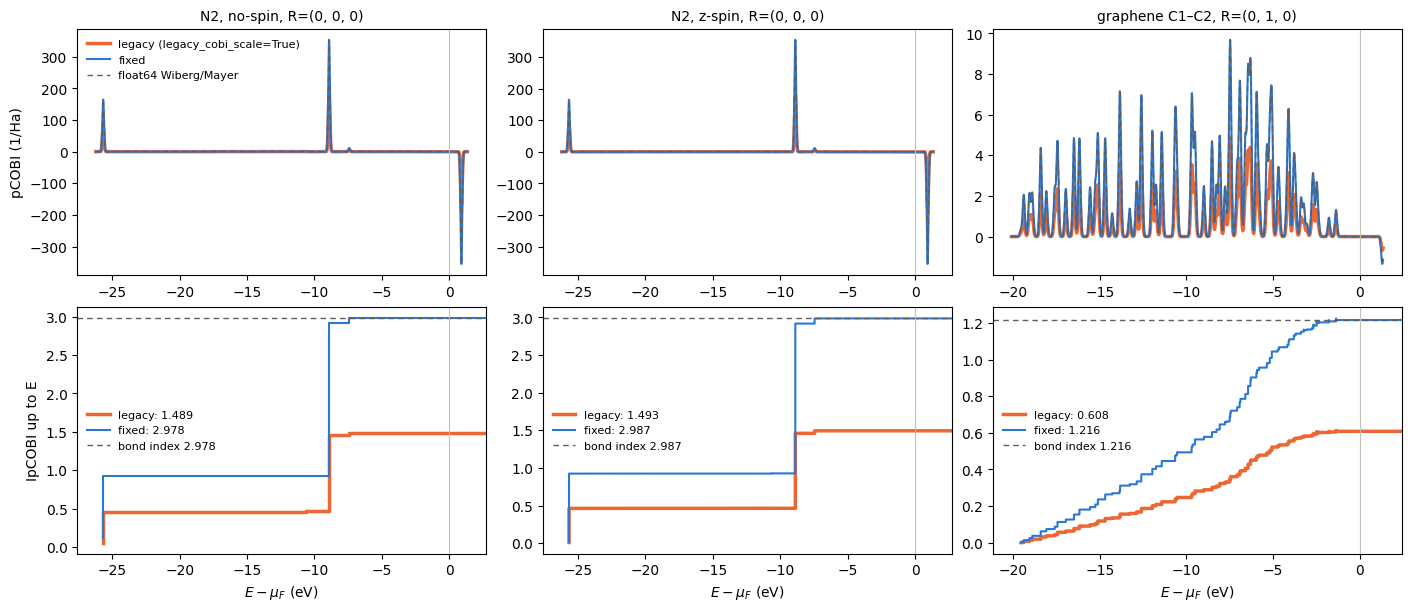

,R,IpCOBI legacy,IpCOBI fixed,Wiberg/Mayer (float64),fixed / Wiberg,legacy / Wiberg
"N2, no-spin","(0, 0, 0)",1.488811,2.977623,2.977623,1.0,0.5
"N2, z-spin","(0, 0, 0)",1.493494,2.986989,2.986992,0.999999,0.5
graphene C1–C2,"(0, 1, 0)",0.608077,1.216154,1.216154,1.0,0.5


In [2]:
COBI_SYSTEMS = {"N2, no-spin": D / "N2_nospin", "N2, z-spin": D / "N2_bare_min",
                "graphene C1–C2": D / "graphene_zspin_full"}
cobi, rows = {}, {}
for name, calc_dir in COBI_SYSTEMS.items():
    eds = {"legacy": quiet(load_edata_at, "F16", False, calc_dir), "fixed": quiet(load_edata_at, "F16", True, calc_dir)}
    ed = eds["fixed"]
    R = quiet(get_pair_images, ed, idcs1=0, idcs2=1)[0]["R"]
    ref = Reference(ed, energy_shift=ed.mu, wiberg_cobi=True, lowdin_rtol=LOWDIN_RTOL)
    A, B = orb_idcs(ed, 0, None), orb_idcs(ed, 1, None)
    er = np.arange(ed.e_tj.min() - 0.02, ed.mu + 0.05, 0.0005, dtype=np.float32)
    entry = {"edata": ed, "erange": er,
             "reference": reference_spectrum(ed, ref.weights_tj(A, B, "cobi", R), er, SIGMA_DEFAULT)}
    for tag, e in eds.items():
        entry[tag] = np.asarray(quiet(get_pcobi, e, idcs1=0, idcs2=1, erange=er, **NOCACHE)[1])
        entry[f"{tag} running"] = quiet(get_ipcobi, e, idcs1=0, idcs2=1, use_cache=False)
    cobi[name] = entry
    rows[name] = {"R": R, "IpCOBI legacy": last_value(entry["legacy running"]),
                  "IpCOBI fixed": last_value(entry["fixed running"]),
                  "Wiberg/Mayer (float64)": ref.integrated(A, B, "cobi", R)}
cobi_table = pd.DataFrame(rows).T
cobi_table["fixed / Wiberg"] = cobi_table["IpCOBI fixed"] / cobi_table["Wiberg/Mayer (float64)"]
cobi_table["legacy / Wiberg"] = cobi_table["IpCOBI legacy"] / cobi_table["Wiberg/Mayer (float64)"]

fig, axes = plt.subplots(2, 3, figsize=(14, 6), layout="constrained")
for col, (name, entry) in enumerate(cobi.items()):
    x = to_ev_rel_mu(entry["edata"], entry["erange"])
    top, bottom = axes[0, col], axes[1, col]
    top.plot(x, entry["legacy"], color=LEGACY_C, linewidth=2.5, label="legacy (legacy_cobi_scale=True)")
    top.plot(x, entry["fixed"], color=FIXED_C, linewidth=1.5, label="fixed")
    top.plot(x, entry["reference"], color=REF_C, linewidth=1, linestyle=(0, (4, 3)), label="float64 Wiberg/Mayer")
    top.set_title(f"{name}, R={cobi_table.loc[name, 'R']}", fontsize=10)
    for tag, color, lw in [("legacy", LEGACY_C, 2.5), ("fixed", FIXED_C, 1.5)]:
        es, cs = entry[f"{tag} running"]
        bottom.step(to_ev_rel_mu(entry["edata"], np.ravel(es)), np.ravel(cs), where="post", color=color, linewidth=lw,
                    label=f"{tag}: {cobi_table.loc[name, f'IpCOBI {tag}']:.3f}")
    bottom.axhline(cobi_table.loc[name, "Wiberg/Mayer (float64)"], color=REF_C, linewidth=1, linestyle=(0, (4, 3)),
                   label=f"bond index {cobi_table.loc[name, 'Wiberg/Mayer (float64)']:.3f}")
    bottom.set_xlim(top.get_xlim())
    bottom.set_xlabel(r"$E - \mu_F$ (eV)")
    bottom.legend(frameon=False, fontsize=8)
    for ax in (top, bottom):
        ax.axvline(0, color="#c3c2b7", linewidth=0.8)
axes[0, 0].set_ylabel("pCOBI (1/Ha)")
axes[1, 0].set_ylabel("IpCOBI up to E")
axes[0, 0].legend(frameon=False, fontsize=8)
savefig(fig, "F16_pcobi_scale")
plt.show()
cobi_table

The analytic case behind the scale: closed-shell H₂ in a minimal orthonormal basis, one occupied band
$C=(1,1)/\sqrt2$ and one empty band $(1,-1)/\sqrt2$, so $D_{12}=\tfrac12$ per spin and the Wiberg index
$(2D_{12})^2=1$. It goes through crawfish's own kernels (`get_h_s_d_t_uv`, `_compute_pcobi_tj`), once as one
no-spin state of weight 2 and once as two spin channels of weight 1.

In [3]:
from crawfish.core.operations.matrix import get_h_s_d_t_uv
from crawfish.funcs.pcohp import _compute_pcobi_tj

h2_rows = {}
for nspin, label in [(1, "no-spin (one state, w = 2)"), (2, "z-spin (two channels, w = 1)")]:
    coef = np.repeat((np.array([[1, 1], [1, -1]], dtype=np.complex64) / np.sqrt(2))[None], nspin, axis=0)
    occ = np.repeat(np.array([[1.0, 0.0]], dtype=np.float32), nspin, axis=0)
    _, _, d_t_uv = get_h_s_d_t_uv(coef, coef, np.repeat(np.array([[-0.5, 0.3]], np.float32), nspin, axis=0), occ)
    wk = np.full(nspin, 2.0 / nspin, dtype=np.float32)
    h2_rows[label] = {f"IpCOBI, {tag}": float(np.sum(occ * _compute_pcobi_tj(
        SimpleNamespace(coef_tju=coef, d_t_uv=d_t_uv, wk_t=wk, legacy_matrices=False, legacy_cobi_scale=legacy),
        [0], [1], "all"))) for tag, legacy in [("fixed", False), ("legacy", True)]}
h2_table = pd.DataFrame(h2_rows).T
h2_table

,"IpCOBI, fixed","IpCOBI, legacy"
"no-spin (one state, w = 2)",1.0,0.5
"z-spin (two channels, w = 1)",1.0,0.5


## F17: default energy grid (implemented)

**Before.** Without an `erange`, spectra were evaluated on a grid of step `res` = 10 mHa, from 10 `res` below the
lowest eigenvalue to 10 `res` above the highest. The default Gaussian, `sig` $=10^{-5}$ Ha², has $s=2.24$ mHa.

**What was wrong.**
- A step of $h=4.5\,s$ doesn't resolve a peak. On the grid, a peak of unit weight at a distance $x_0$ from the
  nearest grid point has the area
  $h\sum_ng(nh-x_0)=1+2\sum_{k\ge1}e^{-2\pi^2k^2s^2/h^2}\cos(2\pi kx_0/h)$, between 0.29 and 1.78 for the defaults.
  Peak heights and areas of default spectra were off accordingly: the N2 N1–N2 pCOHP integrated over the grid to
  −1.02 Ha up to mid-gap, against the exact −0.87 Ha.
- At a fine `res`, the pad of 10 `res` is a fraction of $s$ (0.45 $s$ at `res` = 0.1 mHa), so the lowest and highest
  peaks were cut: the N2 DOS integrated to 0.976 of the state count.

**What changed** (`funcs/general.RES_DEFAULT`, `_resolve_erange`, `_warn_if_grid_too_coarse`;
`utils/arg_correction.get_erange`). The default `res` is 1 mHa $=0.45\,s$. An automatic grid is padded by
$\max(10\,\texttt{res},\,5s)$ for Gaussian spectra (10 `res` for LTI), and every function that needs the grid of one
call (the spectrum, its cache path, the returned `erange`) gets it from one helper. A grid step above $2s$, where peak
areas are off by more than 1%, warns. No legacy switch: at `res=0.01` the pad is still 10 `res`, so `res=0.01` gives the
old grid and the old spectra bit for bit. The spectrum cache is keyed by the grid, so new grids are new entries.

**Now.** Default spectra integrate to their exact sums: the DOS to $\sum_tw_t\,n_{\rm bands}$, the N2 pCOHP to
−0.8668 Ha up to mid-gap. Integrated spectra (`get_i*`) were and are exact sums.

| issue | example below |
|---|---|
| a peak's area depends on where it falls between grid points | one peak's area vs. its offset, old and new default |
| wrong default spectra | N2 DOS and N1–N2 pCOHP on the old and new default grids, and the pCOHP's grid integral vs. the exact one |
| fine grids cut the outer peaks | DOS integral vs. `res`, old and new padding (table) |

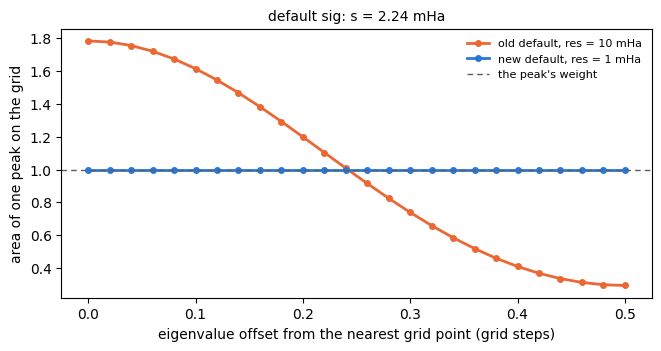

,min,max
"old default, res = 10 mHa",0.292899,1.784287
"new default, res = 1 mHa",1.000000,1.000000


In [4]:
from crawfish.core.operations.vector import get_gauss_smear_spectrum

offsets = np.linspace(0, 0.5, 26)  # eigenvalue position between two grid points, in grid steps
std = float(np.sqrt(SIGMA_DEFAULT / 2))
peak_area = {}
for label, res in {"old default, res = 10 mHa": float(OLD_RES), "new default, res = 1 mHa": float(RES_DEFAULT)}.items():
    grid = np.arange(-0.2, 0.2, res, dtype=np.float32)
    areas = []
    for x0 in offsets:
        e0 = np.float32(grid[len(grid) // 2] + x0 * res)
        spec = get_gauss_smear_spectrum(grid, np.array([[[[[e0]]]]], np.float32), np.ones((1, 1, 1, 1, 1), np.float32),
                                        SIGMA_DEFAULT, normalize=True)[0]
        areas.append(trapezoid(spec, grid))
    peak_area[label] = np.array(areas)

fig, ax = plt.subplots(figsize=(6.5, 3.4), layout="constrained")
for (label, areas), color in zip(peak_area.items(), [LEGACY_C, FIXED_C]):
    ax.plot(offsets, areas, color=color, linewidth=2, marker="o", markersize=4, label=label)
ax.axhline(1, color=REF_C, linewidth=1, linestyle=(0, (4, 3)), label="the peak's weight")
ax.set_xlabel("eigenvalue offset from the nearest grid point (grid steps)")
ax.set_ylabel("area of one peak on the grid")
ax.set_title(f"default sig: s = {1e3 * std:.2f} mHa", fontsize=10)
ax.legend(frameon=False, fontsize=8)
savefig(fig, "F17_peak_area")
plt.show()
pd.DataFrame({label: {"min": a.min(), "max": a.max()} for label, a in peak_area.items()}).T

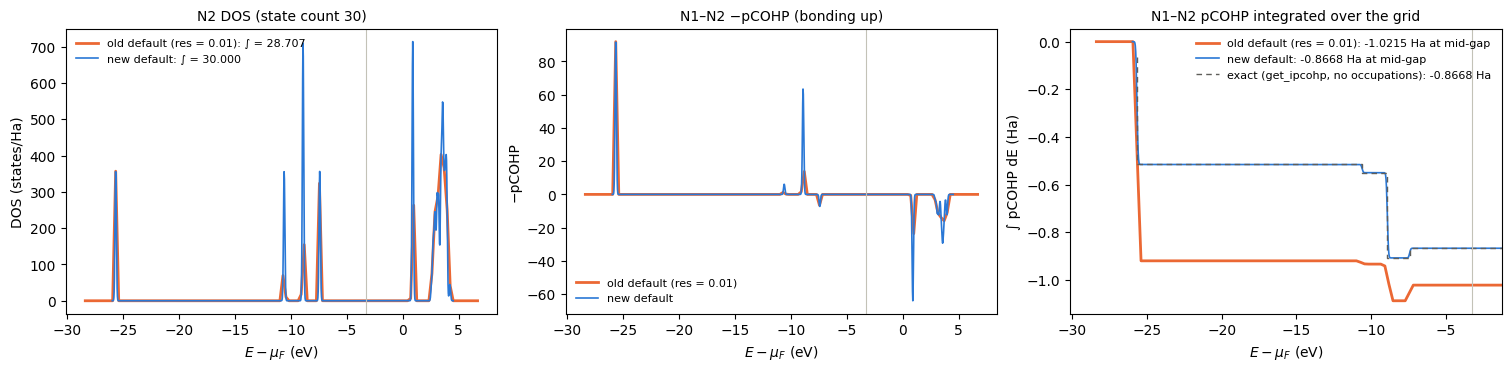

{'old default (res = 0.01)': (130, 'warns'),
 'new default': (1122, 'no warning')}

In [5]:
n2 = quiet(load_edata, D / "N2_nospin")
e_cut = mid_gap(n2)
es, cs = get_ipcohp(n2, idcs1=0, idcs2=1, use_fillings=False, use_cache=False)
es, cs = np.ravel(es), np.ravel(cs)
exact_pcohp = float(cs[es < e_cut][-1])
grids, grid_warnings = {}, {}
for label, kw in {"old default (res = 0.01)": {"res": OLD_RES}, "new default": {}}.items():
    (er, dos), grid_warnings[label] = caught(get_dos, n2, **kw)
    er_c, pcohp = quiet(get_pcohp, n2, idcs1=0, idcs2=1, **kw, **NOCACHE)
    grids[label] = {"erange": er, "dos": np.asarray(dos), "pcohp": np.asarray(pcohp)}
old_grid = np.arange(np.min(n2.e_sabcj) - 10 * OLD_RES, np.max(n2.e_sabcj) + 10 * OLD_RES, OLD_RES, dtype=np.float32)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), layout="constrained")
for (label, g), color, lw in zip(grids.items(), [LEGACY_C, FIXED_C], [2, 1.2]):
    x = to_ev_rel_mu(n2, g["erange"])
    axes[0].plot(x, g["dos"], color=color, linewidth=lw,
                 label=f"{label}: ∫ = {trapezoid(g['dos'], g['erange']):.3f}")
    axes[1].plot(x, -g["pcohp"], color=color, linewidth=lw, label=label)
    run = cumulative_trapezoid(g["pcohp"], g["erange"], initial=0)
    axes[2].plot(x, run, color=color, linewidth=lw, label=f"{label}: {np.interp(e_cut, g['erange'], run):+.4f} Ha at mid-gap")
axes[2].step(to_ev_rel_mu(n2, es), cs, where="post", color=REF_C, linewidth=1, linestyle=(0, (4, 3)),
             label=f"exact (get_ipcohp, no occupations): {exact_pcohp:+.4f} Ha")
axes[0].set_title(f"N2 DOS (state count {float(n2.wk_t.sum()) * n2.nbands:.0f})", fontsize=10)
axes[1].set_title("N1–N2 −pCOHP (bonding up)", fontsize=10)
axes[2].set_title("N1–N2 pCOHP integrated over the grid", fontsize=10)
axes[0].set_ylabel("DOS (states/Ha)")
axes[1].set_ylabel("−pCOHP")
axes[2].set_ylabel("∫ pCOHP dE (Ha)")
for ax in axes:
    ax.axvline(to_ev_rel_mu(n2, e_cut), color="#c3c2b7", linewidth=0.8)
    ax.set_xlabel(r"$E - \mu_F$ (eV)")
    ax.legend(frameon=False, fontsize=8)
axes[2].set_xlim(right=to_ev_rel_mu(n2, e_cut) + 2)
savefig(fig, "F17_default_grid")
plt.show()
{label: (len(g["erange"]), "warns" if grid_warnings[label] else "no warning") for label, g in grids.items()}

In [6]:
# DOS integral / state count for several res: the old padding (10 res, rebuilt by hand) vs. now
pad_rows = {}
for res in [0.01, 0.003, 0.001, 0.0003, 0.0001]:
    res = np.float32(res)
    old_pad = np.arange(np.min(n2.e_sabcj) - 10 * res, np.max(n2.e_sabcj) + 10 * res, res, dtype=np.float32)
    e_now, d_now = quiet(get_dos, n2, res=res)
    d_old = quiet(get_dos, n2, erange=old_pad)[1]
    count = float(n2.wk_t.sum()) * n2.nbands
    pad_rows[f"{float(res):g}"] = {"step / s": float(res) / std, "old padding": trapezoid(d_old, old_pad) / count,
                                   "now": trapezoid(d_now, e_now) / count,
                                   "pad now (s)": float(np.min(n2.e_tj) - e_now[0]) / std}
pad_table = pd.DataFrame(pad_rows).T
pad_table.index.name = "res (Ha)"
pad_table.round(4)

,step / s,old padding,now,pad now (s)
res (Ha),,,,
0.01,4.4721,0.9569,0.9569,44.7214
0.003,1.3416,1.0000,1.0000,13.4164
0.001,0.4472,1.0000,1.0000,5.0000
0.0003,0.1342,0.9933,1.0000,5.0000
0.0001,0.0447,0.9756,1.0000,5.0000


## F18: `|projection|^2` bandProjections files (implemented; bug fix)

**Before.** With `band-projection-params <ortho> yes`, which is also JDFTx's default when the command is missing,
JDFTx writes $|T_{\mu,j}(t)|^2$ instead of $T$. crawfish used those values as if they were $T$:
- pDOS squared them again: $\sum_{j,t}w_t|T_{\mu,j}|^4\,\delta(E-\epsilon_j(t))$;
- with `los_orbs=True` (default) the Löwdin step ran on them, building "orthonormal orbitals" from magnitudes, and the
  too-few-bands check flagged every state;
- `orbital_completeness_u` summed $|T|^4$, and `orbital_span_t` was meaningless;
- the guard on the pair functions was commented out (its decorator replaced the `ElecData` argument by `None`), so
  pCOHP, pCOOP, pCOBI and pCOMO returned numbers.

**What was wrong.** All of these, and pair spectra can't be computed without phases at all. For `N2_nospin`,
N #1's occupied s pDOS came out 1.000 (default) or 0.451 (`los_orbs=False`) instead of 1.584, and the N–N IpCOHP
−0.60 Ha instead of −0.87 Ha.

**What changed** (`ElecData.projections_are_norms`, `_file_proj_to_amplitude`, `alloc_elec_data`;
`utils/arg_correction._assert_complex_bandprojections`, now called by each `funcs/pcohp._get_<mode>_tj`). crawfish
uses the amplitudes $|T|=\sqrt{\text{file value}}$ as a real `proj_tju`, so pDOS $\sum w_t|T|^2\delta$ and
`orbital_completeness_u` come out right. The Löwdin step and the band-span check are skipped: `los_orbs` is switched
off on load with one warning, and can't be switched back on. `orbital_span_t` and the eight pair functions raise a
`ValueError` saying the second argument of `band-projection-params` must be `no`. The cache keeps the raw file
values, as before, so caches written before the fix give the right result. Meshes reduced by time reversal only are
still unfolded ($|T(-k)|=|T(k)|$); point-group-reduced ones stay guarded, since rotating orbitals needs phases. No
legacy switch: bug fix.

**Now.** pDOS per orbital equals the complex file's with `los_orbs=False`, to the 7 printed decimals of $|T|^2$.

| issue | example below |
|---|---|
| pDOS of $\|T\|^4$, Löwdin step on magnitudes | N #1 s and px pDOS: before (default, and `los_orbs=False`), now, complex file |
| pair spectra from $\|T\|^2$ | the error the pair functions now raise |

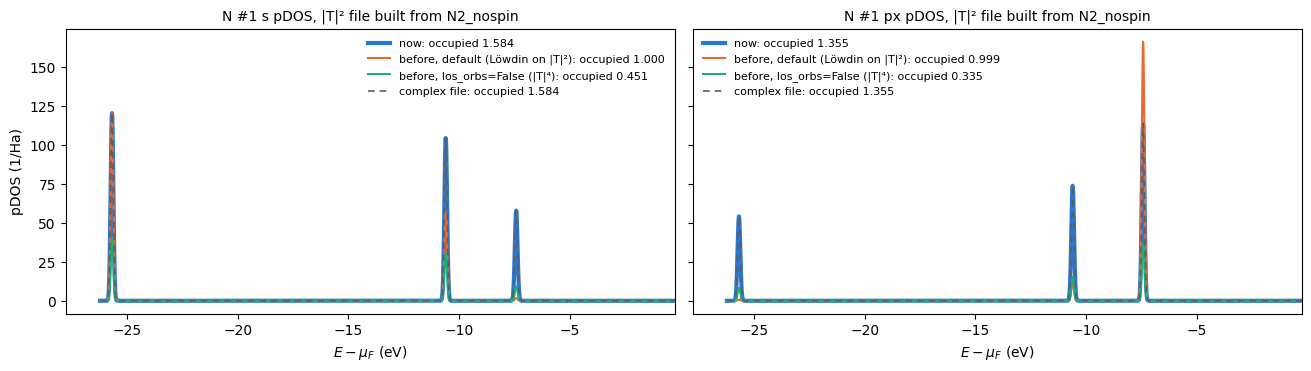

,"before, default (Löwdin on |T|²)","before, los_orbs=False (|T|⁴)",now,complex file
occupied pDOS of N #1,,,,
px,0.99902,0.33488,1.35471,1.35471
py,0.50507,0.36052,0.97912,0.97912
pz,0.50507,0.36052,0.97912,0.97912
s,1.00003,0.45130,1.58380,1.58380


In [7]:
from crawfish.utils.testing import write_norm_bandprojections
from crawfish.io.data_parsing import get_proj_tju_from_file
from crawfish.core.operations.matrix import los_projs_for_orbs
from crawfish.funcs.dos import get_pdos_tj

norm_dir = TMP / "N2_nospin_norm"
shutil.copytree(D / "N2_nospin", norm_dir, ignore=shutil.ignore_patterns(".crawfish_cache"))
write_norm_bandprojections(D / "N2_nospin" / "bandProjections", norm_dir / "bandProjections")
norm_ed, norm_msgs = caught(ElecData, norm_dir)
cplx = quiet(load_edata, D / "N2_nospin", los_orbs=False)  # the reference: sum_j w |T|^2 from the complex file
# Before F18 the raw file values were the projections, Löwdin-orthonormalized by default (the same functions the old
# code path called)
raw = get_proj_tju_from_file(norm_dir / "bandProjections")
proj_versions = {"before, default (Löwdin on |T|²)": quiet(los_projs_for_orbs, raw),
                 "before, los_orbs=False (|T|⁴)": raw, "now": norm_ed.proj_tju, "complex file": cplx.proj_tju}
colors = {"before, default (Löwdin on |T|²)": LEGACY_C, "before, los_orbs=False (|T|⁴)": THIRD_C, "now": FIXED_C,
          "complex file": REF_C}
e_cut_n2 = mid_gap(cplx)
er = np.arange(cplx.e_tj.min() - 0.02, cplx.e_tj.max() + 0.02, 0.0005, dtype=np.float32)
pdos_occ, pdos_spec = {}, {}
for orb in ["s", "py", "pz", "px"]:
    orbs = orb_idcs(cplx, 0, orb)
    for name, proj in proj_versions.items():
        w_tj = get_pdos_tj(proj, orbs, norm_ed.wk_t)
        es_, cs_ = get_generic_integrate(norm_ed, w_tj)
        pdos_occ[(orb, name)] = float(np.ravel(cs_)[np.ravel(es_) < e_cut_n2][-1])
        pdos_spec[(orb, name)] = np.asarray(get_generic_spectrum(norm_ed, w_tj, erange=er)[1])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True, layout="constrained")
plot_order = ["now", "before, default (Löwdin on |T|²)", "before, los_orbs=False (|T|⁴)", "complex file"]
for ax, orb in zip(axes, ["s", "px"]):
    for name in plot_order:  # "now" first and thickest, so the curves drawn over it stay visible
        style = dict(linestyle=(0, (4, 3)), linewidth=1.2) if name == "complex file" else dict(linewidth=3 if name == "now" else 1.5)
        ax.plot(to_ev_rel_mu(cplx, er), pdos_spec[(orb, name)], color=colors[name], **style,
                label=f"{name}: occupied {pdos_occ[(orb, name)]:.3f}")
    ax.set_title(f"N #1 {orb} pDOS, |T|² file built from N2_nospin", fontsize=10)
    ax.set_xlabel(r"$E - \mu_F$ (eV)")
    ax.set_xlim(right=to_ev_rel_mu(cplx, e_cut_n2) + 3)
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("pDOS (1/Ha)")
savefig(fig, "F18_norm_pdos")
plt.show()
f18_table = pd.Series(pdos_occ).unstack()[list(proj_versions)]
f18_table.index.name = "occupied pDOS of N #1"
f18_table.round(5)

In [8]:
try:
    get_ipcohp(norm_ed, idcs1=0, idcs2=1)
    pair_error = None
except ValueError as err:
    pair_error = str(err)
print("load warning:", norm_msgs[0][:200], "...")
print("get_ipcohp:", pair_error)
print("settings:", get_edata_settings_str(norm_ed))

load warning: This bandProjections file holds |projection|^2 (band-projection-params <ortho> yes, JDFTx's default), so it supports DOS and pDOS only, from the amplitudes |T|: los_orbs is switched off (the orbitals  ...
get_ipcohp: This bandProjections file holds |projection|^2, without phases, so pair spectra (pCOHP, pCOOP, pCOBI, pCOMO) can't be computed from it; DOS and pDOS still work. Rerun JDFTx with the second argument of band-projection-params set to 'no' (complex projections), e.g. 'band-projection-params yes no' (finding F18).
settings: lgcb_False_lgfl_False_lgri_False_lglw_False_lgmt_False_lgnm_False_lgph_False_lgkm_False_lou_False_h-en_True_p-c_True_trimj_False_upg_True_utr_True


## F19: an atom with its own periodic images (implemented; new capability)

**Before.** The pair functions refused orbital sets that share an orbital ("Orbitals cannot be repeated between
sets"), and the weight kernel `_get_gen_tj_block` left out every term with $\mu=\nu$:

$$
pX(E)=\sum_{j,t}w_t\sum_{\mu\in A,\ \nu\in B,\ \mu\neq\nu}\mathrm{Re}\big[C^*_{\mu,j}\,M_{\mu\nu}(R)\,e^{2\pi ik_t\cdot R}\,C_{\nu,j}\big]\,\delta\big(E-\epsilon_j(t)\big).
$$

**What was wrong.** For $R=0$ that is right: $\mu=\nu$ in the same cell is an on-site term, not a pair interaction.
For $R\neq0$, orbital $\mu$ in cell 0 and its copy in cell $R$ belong to two different atoms. So an atom's
interaction with its own images (graphene's second neighbours, every bond of a one-atom cell such as fcc Al) was
unreachable, and the kernel alone kept only the $\mu\neq\nu$ part: 49.8% of graphene's C #1–C #1 IpCOHP at
$R=(1,0,0)$, and 69.4% of wurtzite ZnO's Zn #1–Zn #1.

**What changed** (`funcs/pcohp._compute_signed_tj`, `core/operations/matrix._get_gen_tj_block`,
`utils/arg_correction.check_repeat`; new `utils/lattice.get_nearest_images`, exported from `crawfish.funcs`). The
kernel takes a mask of the terms to include: $\mu=\nu$ is included for atom pairs whose image is $R\neq0$, and still
left out for $R=0$ and `image="all"`. Orbital sets may share orbitals only for an explicit lattice vector other than
$(0,0,0)$; otherwise the error explains why and points to `image=<lattice vector>`. `get_nearest_images(edata, a, b)`
lists the images of atom $b$ nearest to atom $a$ at a non-zero distance. Every call that was valid before returns
bit-identical weights (49 weight arrays checked on N2, graphene and ZnO). The spectrum cache now keeps lattice vectors
in order: since F3, $(1,0,0)$ and $(0,1,0)$ had shared a cached spectrum. Like any $R\neq0$, this needs the full k-mesh;
the fcc Al test calculations have a reduced mesh without a `sym` file and stay refused.

**Now.** C #1 with each of its six second-neighbour images matches the float64 value including $\mu=\nu$. The six
totals are equal, as symmetry requires, but the $\mu=\nu$ share depends on the direction: 50% along $R=(\pm1,0,0)$
and 15% for the other four, so the old $\mu\neq\nu$-only values didn't even agree between equivalent bonds. $R$ and
$-R$ agree.

| issue | example below |
|---|---|
| self-image bonds unreachable, $\mu=\nu$ left out | C #1–C #1 pCOHP at $R=(1,0,0)$: all terms vs. $\mu\neq\nu$ only vs. float64, and its running integral; IpCOHP of all six images (table) |

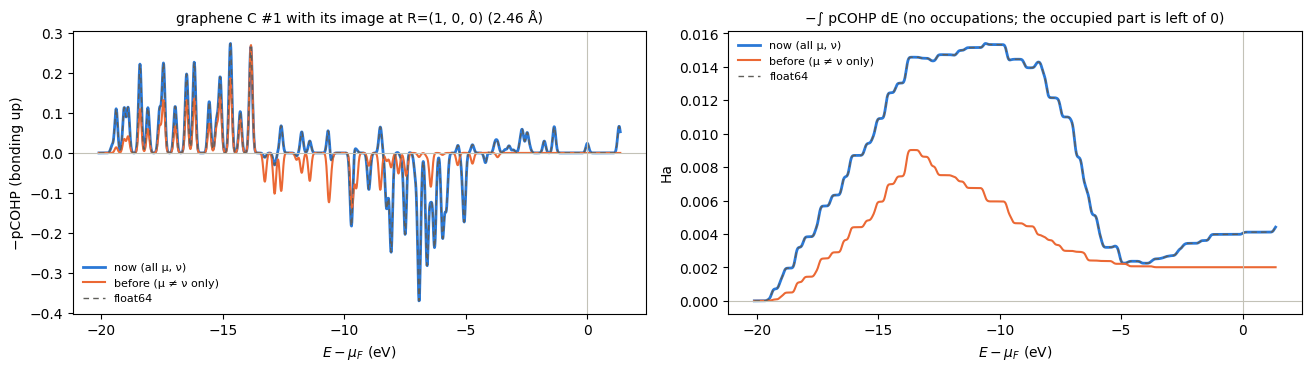

,distance (Å),IpCOHP now,"float64 (all μ, ν)",μ ≠ ν only (before),IpCOBI now,μ = ν share
"(0, -1, 0)",2.459986,-0.004043,-0.004043,-0.003450,0.002807,0.146656
"(0, 1, 0)",2.459986,-0.004043,-0.004043,-0.003450,0.002807,0.146656
"(-1, -1, 0)",2.459986,-0.004043,-0.004043,-0.003450,0.002807,0.146646
"(1, 1, 0)",2.459986,-0.004043,-0.004043,-0.003450,0.002807,0.146646
"(-1, 0, 0)",2.459986,-0.004043,-0.004043,-0.002012,0.002807,0.502383
"(1, 0, 0)",2.459986,-0.004043,-0.004043,-0.002012,0.002807,0.502382


In [9]:
from crawfish.core.operations.matrix import _get_gen_tj_block, get_spin_idx_t


def pre_f19_weights(edata, orbs, R):
    # Self-image pCOHP weights as the pre-F19 kernel computed them: the default mask, u != v only
    phase_t = np.exp(2j * np.pi * edata.ks_t.astype(np.float64) @ np.asarray(R, dtype=np.float64))
    mat_t = edata.get_mat_r_suv("h", R)[get_spin_idx_t(edata.nstates, edata.nspin)]
    mat_t = mat_t[:, orbs][:, :, orbs] * phase_t[:, None, None]
    return _get_gen_tj_block(edata.coef_tju, mat_t, edata.wk_t, orbs, orbs)


gr = quiet(load_edata, D / "graphene_zspin_full")
gr_ref = Reference(gr, energy_shift=gr.mu, lowdin_rtol=LOWDIN_RTOL)
C1 = np.asarray(orb_idcs(gr, 0, None))
second = get_nearest_images(gr, 0, 0)
f19_rows = {}
for img in second:
    R = img["R"]
    now = last_value(get_ipcohp(gr, idcs1=0, idcs2=0, image=R, use_cache=False))
    f19_rows[str(R)] = {"distance (Å)": img["distance"], "IpCOHP now": now,
                        "float64 (all μ, ν)": gr_ref.integrated(list(C1), list(C1), "cohp", R),
                        "μ ≠ ν only (before)": float(np.sum(gr.occ_tj * pre_f19_weights(gr, C1, R))),
                        "IpCOBI now": last_value(get_ipcobi(gr, idcs1=0, idcs2=0, image=R, use_cache=False))}
f19_table = pd.DataFrame(f19_rows).T
f19_table["μ = ν share"] = 1 - f19_table["μ ≠ ν only (before)"] / f19_table["IpCOHP now"]

R = (1, 0, 0)
er_gr = np.arange(gr.e_tj.min() - 0.02, gr.mu + 0.05, 0.0005, dtype=np.float32)
f19_spec = {"now (all μ, ν)": np.asarray(get_pcohp(gr, idcs1=0, idcs2=0, image=R, erange=er_gr, **NOCACHE)[1]),
            "before (μ ≠ ν only)": np.asarray(get_generic_spectrum(gr, pre_f19_weights(gr, C1, R), erange=er_gr)[1]),
            "float64": reference_spectrum(gr, gr_ref.weights_tj(list(C1), list(C1), "cohp", R), er_gr, SIGMA_DEFAULT)}
f19_styles = {"now (all μ, ν)": dict(color=FIXED_C, linewidth=2), "before (μ ≠ ν only)": dict(color=LEGACY_C, linewidth=1.5),
              "float64": dict(color=REF_C, linewidth=1, linestyle=(0, (4, 3)))}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), layout="constrained")
x = to_ev_rel_mu(gr, er_gr)
for name, spec in f19_spec.items():
    axes[0].plot(x, -spec, label=name, **f19_styles[name])
    axes[1].plot(x, -cumulative_trapezoid(spec, er_gr, initial=0), label=name, **f19_styles[name])
axes[0].set_title(f"graphene C #1 with its image at R={R} ({second[0]['distance']:.2f} Å)", fontsize=10)
axes[0].set_ylabel("−pCOHP (bonding up)")
axes[1].set_title("−∫ pCOHP dE (no occupations; the occupied part is left of 0)", fontsize=10)
axes[1].set_ylabel("Ha")
for ax in axes:
    ax.axvline(0, color="#c3c2b7", linewidth=0.8)
    ax.axhline(0, color="#c3c2b7", linewidth=0.8)
    ax.set_xlabel(r"$E - \mu_F$ (eV)")
    ax.legend(frameon=False, fontsize=8)
savefig(fig, "F19_self_image")
plt.show()
f19_table

## F20: pair spectra of calculations without smearing (implemented; bug fix)

**Before.** With `norm_eigs_for_h=True` (default), $H$ is built from $\epsilon_j-\mu_F$. JDFTx prints $\mu_F$ only with
`elec-smearing`, and `ElecData.mu` raised without it, so the default pCOHP, pCOOP, pCOBI and pCOMO of any calculation
without smearing raised. The legacy matrices read $\mu_F$ even with `norm_eigs_for_h=False`.

**What was wrong.** These spectra need only an energy zero. Its value changes pair values only in the non-orthogonal
basis, or where a Löwdin direction was dropped (F15), and any level in the gap is as good as JDFTx's own $\mu_F$,
which can sit anywhere there.

**What changed** (`ElecData.mu` with `_resolve_mu`, `_estimate_mu_from_gap` and `mu_is_estimated`; `set_mat_uv`,
`set_mat_uu`; `_switch_off_norm_eigs_without_mu` as the fallback). Without a $\mu_F$ in the outfile and none set by
hand, `edata.mu` is the midpoint of the HOMO (highest $\epsilon_j(t)$ with $f_j(t)\ge0.5$) and the LUMO (lowest with
$f_j(t)\le0.5$), the definitions of JDFTx's `eigStats` dump, and crawfish warns the first time it is used (not on
load). That needs occupations that don't depend on $\mu_F$: a `fillings` file, or no smearing; a smeared run without
either still raises. `norm_eigs_for_h` stays on. When spin channels or k-points are filled separately, the HOMO can
lie above the LUMO; the warning then says the value is only an energy zero. Only without a LUMO (no empty band) is
`norm_eigs_for_h` switched off (settings string `h-en_False`), warning where that matters. `edata.mu = ...`
overrides the estimate; a hand-set $\mu_F$ isn't part of the cache key, so follow it with `edata.reset_cache()`
(below, a fresh copy of the run does the same). No legacy switch: bug fix. (A first version of this fix switched `norm_eigs_for_h` off for
every run without $\mu_F$; the midpoint replaced it.)

**Now.** Default pair spectra of such runs work. In the Löwdin basis (nothing dropped) they don't depend on the
energy zero, so they equal the same run with its printed $\mu_F$. In the non-orthogonal basis they are measured from
the gap midpoint, which differs from JDFTx's $\mu_F$ where a run has one ($-0.2199$ Ha vs. $-0.1000$ Ha for N2), and
`edata.mu = ...` restores any other zero.

| issue | example below |
|---|---|
| default pair spectra raised | N1–N2 pCOHP of `N2_nospin` without its $\mu_F$: Löwdin and non-orthogonal bases, midpoint vs. unshifted vs. $\mu_F$ set by hand vs. the original run |
| real runs without smearing | the two Si runs: the estimate vs. `eigStats`, and their all-image Si–Si IpCOHP (table) |

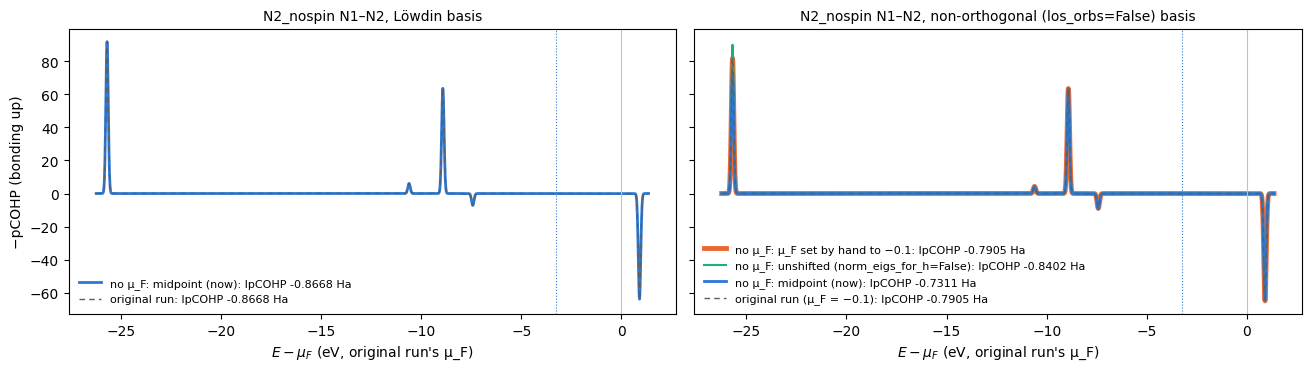

loading the run without μ_F warned: []
first read of edata.mu: No chemical potential in the outfile (JDFTx prints one only with elec-smearing), so edata.mu is the midpoint of the HOMO (-0.372778 Ha) and LUMO (-0.066932 Ha): -0.219855 Ha. To override, set edata.mu and call edata.reset_cache() (cached results don't record mu; finding F20).


,Si_nosmear_nospin,Si_nosmear_zspin_M2
HOMO,0.229427,0.360618
LUMO,0.255089,0.103210
edata.mu (midpoint),0.242258,0.231914
eigStats HOMO,0.229427,0.360618
eigStats LUMO,0.255089,0.103210
eigStats 'mu' (findMu),0.241911,0.239815
IpCOHP Löwdin,-0.675883,-0.545834
"IpCOHP non-orth., midpoint",-0.599930,-0.467331
"IpCOHP non-orth., unshifted",-0.485089,-0.386296


In [10]:
import re

nomu_dir = TMP / "N2_nospin_nomu"
shutil.copytree(D / "N2_nospin", nomu_dir, ignore=shutil.ignore_patterns(".crawfish_cache"))
lines = (nomu_dir / "out").read_text().splitlines()
(nomu_dir / "out").write_text("\n".join(line for line in lines if "FillingsUpdate:" not in line) + "\n")
nomu, nomu_msgs = caught(ElecData, nomu_dir)  # warnings raised on load (none expected)
nomu_mu, mu_msgs = caught(lambda: nomu.mu)  # the first read announces the estimate
orig = quiet(load_edata, D / "N2_nospin")
# A hand-set mu isn't part of the cache key, so results cached with the estimate in nomu_dir would be reused: set it
# in a fresh copy (or call edata.reset_cache() after setting it)
hand_dir = TMP / "N2_nospin_nomu_by_hand"
shutil.copytree(nomu_dir, hand_dir, ignore=shutil.ignore_patterns(".crawfish_cache"))
by_hand = quiet(load_edata, hand_dir, los_orbs=False)
by_hand.mu = orig.mu
f20_versions = {
    "Löwdin": {"no μ_F: midpoint (now)": nomu, "original run": orig},
    "non-orthogonal (los_orbs=False)": {  # drawn in this order, so the thinner lines stay visible on top
        "no μ_F: μ_F set by hand to −0.1": by_hand,
        "no μ_F: unshifted (norm_eigs_for_h=False)": quiet(load_edata, nomu_dir, los_orbs=False, norm_eigs_for_h=False),
        "no μ_F: midpoint (now)": quiet(load_edata, nomu_dir, los_orbs=False),
        "original run (μ_F = −0.1)": quiet(load_edata, D / "N2_nospin", los_orbs=False)}}
f20_styles = {"no μ_F: midpoint (now)": dict(color=FIXED_C, linewidth=2),
              "no μ_F: unshifted (norm_eigs_for_h=False)": dict(color=THIRD_C, linewidth=1.5),
              "no μ_F: μ_F set by hand to −0.1": dict(color=LEGACY_C, linewidth=3.5),
              "original run": dict(color=REF_C, linewidth=1, linestyle=(0, (4, 3))),
              "original run (μ_F = −0.1)": dict(color=REF_C, linewidth=1, linestyle=(0, (4, 3)))}
er_n2 = np.arange(orig.e_tj.min() - 0.02, orig.mu + 0.05, 0.0005, dtype=np.float32)
f20_ipcohp = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True, layout="constrained")
for ax, (basis, versions) in zip(axes, f20_versions.items()):
    for name, ed in versions.items():
        spec = np.asarray(quiet(get_pcohp, ed, idcs1=0, idcs2=1, erange=er_n2, **NOCACHE)[1])
        f20_ipcohp[(basis, name)] = last_value(quiet(get_ipcohp, ed, idcs1=0, idcs2=1, use_cache=False))
        ax.plot(to_ev_rel_mu(orig, er_n2), -spec, label=f"{name}: IpCOHP {f20_ipcohp[(basis, name)]:+.4f} Ha",
                **f20_styles[name])
    ax.set_title(f"N2_nospin N1–N2, {basis} basis", fontsize=10)
    ax.set_xlabel(r"$E - \mu_F$ (eV, original run's μ_F)")
    ax.axvline(0, color="#c3c2b7", linewidth=0.8)
    ax.axvline(to_ev_rel_mu(orig, nomu_mu), color=FIXED_C, linewidth=0.8, linestyle=":")
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("−pCOHP (bonding up)")
savefig(fig, "F20_no_mu")
plt.show()


def eigstats(calc_dir):
    text = (calc_dir / "eigStats").read_text()
    return {key: float(re.search(rf"{key}\s*: (\S+)", text)[1]) for key in ("HOMO", "LUMO", "mu")}


si_rows = {}
for name in ["Si_nosmear_nospin", "Si_nosmear_zspin_M2"]:
    eds = {los: quiet(load_edata, D / name, los_orbs=los) for los in (True, False)}
    unshifted = quiet(load_edata, D / name, los_orbs=False, norm_eigs_for_h=False)
    es = eigstats(D / name)
    homo, lumo = eds[True]._mu_gap if eds[True].mu_is_estimated else (np.nan, np.nan)
    si_rows[name] = {"HOMO": homo, "LUMO": lumo, "edata.mu (midpoint)": quiet(lambda: eds[True].mu),
                     "eigStats HOMO": es["HOMO"], "eigStats LUMO": es["LUMO"], "eigStats 'mu' (findMu)": es["mu"],
                     "IpCOHP Löwdin": last_value(quiet(get_ipcohp, eds[True], idcs1=0, idcs2=1, image="all")),
                     "IpCOHP non-orth., midpoint": last_value(quiet(get_ipcohp, eds[False], idcs1=0, idcs2=1, image="all")),
                     "IpCOHP non-orth., unshifted": last_value(quiet(get_ipcohp, unshifted, idcs1=0, idcs2=1, image="all"))}
si_table = pd.DataFrame(si_rows).T
print("loading the run without μ_F warned:", nomu_msgs)
print("first read of edata.mu:", mu_msgs[0] if mu_msgs else None)
si_table.T

## F15: the energy zero where the Löwdin step dropped a direction (warning only)

Where the Löwdin step dropped an orbital direction, $\sum_jC_jC_j^\dagger$ is a projector, not the identity, so
$H-\mu_FS$ changes off-diagonal $H$ and pair values there depend on `norm_eigs_for_h`. Neither energy zero is "right":
such states aren't converged in the number of bands. The too-few-bands warning now says so. No numbers change.

In [11]:
n2_10, n2_10_msgs = caught(ElecData, D / "N2_nospin_10bands")
band_msg = next(m for m in n2_10_msgs if "Too few bands" in m)
f15 = {"norm_eigs_for_h=True": last_value(get_ipcohp(n2_10, idcs1=0, idcs2=1, use_cache=False))}
n2_10.norm_eigs_for_h = False
f15["norm_eigs_for_h=False"] = last_value(get_ipcohp(n2_10, idcs1=0, idcs2=1, use_cache=False))
print("..." + band_msg[band_msg.find("The Löwdin step"):band_msg.find(" Pair spectra")])
f15

...The Löwdin step (los_orbs) dropped 2 of these combination(s), below 1e-06, so they get no weight there, and pair values at those states also depend on the energy zero of H (norm_eigs_for_h; finding F15).


/Users/richb/vs/crawfish/src/crawfish/core/elecdata.py:732: UserWarning: Too few bands: at 5 of 8 states (62.5% of the k-point weight), an orbital combination is almost missing from the bands (band-space overlap eigenvalue below 0.0001 of the largest; smallest 3.8e-08), mostly N px, N s. The Löwdin step (los_orbs) dropped 2 of these combination(s), below 1e-06, so they get no weight there, and pair values at those states also depend on the energy zero of H (norm_eigs_for_h; finding F15). Pair spectra (and pDOS with los_orbs) rebuild the orbitals from these bands, so they aren't converged in the number of bands, often by several percent. Increase elec-n-bands until edata.orbital_span_t has no small values (notes/theory_audit.md, findings F10 and F11).
  self.alloc_elec_data()


{'norm_eigs_for_h=True': -0.8496987819671631,
 'norm_eigs_for_h=False': -0.8621584177017212}

## Tests

In [12]:
# F16: IpCOBI is the float64 Wiberg/Mayer index; legacy is exactly half; spin types agree; H2 gives 1
for name, row in cobi_table.iterrows():
    assert np.isclose(row["IpCOBI fixed"], row["Wiberg/Mayer (float64)"], rtol=1e-5), name
    assert np.isclose(row["IpCOBI legacy"], row["IpCOBI fixed"] / 2, rtol=1e-6), name
    entry = cobi[name]
    assert np.allclose(entry["fixed"], 2 * entry["legacy"], rtol=1e-6, atol=1e-6), name
    assert np.max(np.abs(entry["fixed"] - entry["reference"])) < 1e-3 * np.max(np.abs(entry["reference"])), name
assert np.isclose(cobi_table.loc["N2, no-spin", "IpCOBI fixed"], cobi_table.loc["N2, z-spin", "IpCOBI fixed"], rtol=0.01)
assert np.isclose(cobi_table.loc["N2, no-spin", "IpCOBI fixed"], 2.977623, atol=1e-5)
assert np.allclose(h2_table["IpCOBI, fixed"], 1.0, atol=1e-6) and np.allclose(h2_table["IpCOBI, legacy"], 0.5, atol=1e-6)
# F17: the old default grid gave peak areas from 0.29 to 1.78; the new one is exact; res=0.01 is the old grid
old_areas, new_areas = peak_area["old default, res = 10 mHa"], peak_area["new default, res = 1 mHa"]
assert np.isclose(old_areas.min(), 0.2929, atol=1e-3) and np.isclose(old_areas.max(), 1.7843, atol=1e-3)
assert np.allclose(new_areas, 1.0, atol=1e-6)
assert np.array_equal(grids["old default (res = 0.01)"]["erange"], old_grid)
new = grids["new default"]
assert np.isclose(trapezoid(new["dos"], new["erange"]), float(n2.wk_t.sum()) * n2.nbands, rtol=1e-4)
below = new["erange"] < e_cut
assert np.isclose(trapezoid(new["pcohp"][below], new["erange"][below]), exact_pcohp, atol=1e-4)
old = grids["old default (res = 0.01)"]
below = old["erange"] < e_cut
assert np.isclose(trapezoid(old["pcohp"][below], old["erange"][below]), -1.021535, atol=1e-5)
assert grid_warnings["old default (res = 0.01)"] and not grid_warnings["new default"]
assert np.isclose(pad_table.loc["0.0001", "old padding"], 0.9756, atol=1e-3) and np.allclose(pad_table.loc[["0.003", "0.001", "0.0003", "0.0001"], "now"], 1, atol=1e-4)
# F18: before (as the old code computed it) vs. now vs. the complex file
assert np.isclose(f18_table.loc["s", "before, default (Löwdin on |T|²)"], 1.00003, atol=1e-4)
assert np.isclose(f18_table.loc["s", "before, los_orbs=False (|T|⁴)"], 0.45130, atol=1e-4)
assert np.allclose(f18_table["now"], f18_table["complex file"], rtol=1e-5) and np.isclose(f18_table.loc["s", "now"], 1.58380, atol=1e-4)
for orb in ["s", "px"]:
    ref_spec = pdos_spec[(orb, "complex file")]
    assert np.max(np.abs(pdos_spec[(orb, "now")] - ref_spec)) < 1e-6 * np.max(np.abs(ref_spec))
assert len(norm_msgs) == 1 and not norm_ed.los_orbs and pair_error is not None and "band-projection-params" in pair_error
# F19: six second neighbours; crawfish equals float64 including u == v, about half of it; R and -R agree
assert len(second) == 6 and np.allclose(f19_table["distance (Å)"], 2.46, atol=1e-3)
assert np.allclose(f19_table["IpCOHP now"], f19_table["float64 (all μ, ν)"], atol=1e-5)
assert np.allclose(f19_table["IpCOHP now"], f19_table["IpCOHP now"].iloc[0], atol=1e-6)  # equivalent bonds
assert np.allclose(f19_table.loc[["(1, 0, 0)", "(-1, 0, 0)"], "μ = ν share"], 0.502, atol=0.005)
assert np.allclose(f19_table.drop(["(1, 0, 0)", "(-1, 0, 0)"])["μ = ν share"], 0.147, atol=0.005)
assert np.isclose(f19_table.loc["(1, 0, 0)", "IpCOHP now"], f19_table.loc["(-1, 0, 0)", "IpCOHP now"], atol=1e-6)
assert np.max(np.abs(f19_spec["now (all μ, ν)"] - f19_spec["float64"])) < 1e-3 * np.max(np.abs(f19_spec["float64"]))
# F20: the run without mu uses the HOMO-LUMO midpoint, announced on first use, not on load
assert nomu.norm_eigs_for_h and nomu.mu_is_estimated and not [m for m in nomu_msgs if "chemical potential" in m]
assert len(mu_msgs) == 1 and "midpoint of the HOMO" in mu_msgs[0] and np.isclose(nomu_mu, -0.219855, atol=1e-6)
assert np.isclose(f20_ipcohp[("Löwdin", "no μ_F: midpoint (now)")], f20_ipcohp[("Löwdin", "original run")], atol=1e-6)
nonortho = {k[1]: v for k, v in f20_ipcohp.items() if k[0] != "Löwdin"}
assert np.isclose(nonortho["no μ_F: μ_F set by hand to −0.1"], nonortho["original run (μ_F = −0.1)"], atol=1e-6)
assert abs(nonortho["no μ_F: midpoint (now)"] - nonortho["original run (μ_F = −0.1)"]) > 1e-2
assert abs(nonortho["no μ_F: midpoint (now)"] - nonortho["no μ_F: unshifted (norm_eigs_for_h=False)"]) > 1e-2
for name, row in si_table.iterrows():
    assert np.isclose(row["HOMO"], row["eigStats HOMO"], atol=1e-6) and np.isclose(row["LUMO"], row["eigStats LUMO"], atol=1e-6)
    assert np.isclose(row["edata.mu (midpoint)"], 0.5 * (row["HOMO"] + row["LUMO"]))
    assert abs(row["IpCOHP non-orth., midpoint"] - row["IpCOHP non-orth., unshifted"]) > 1e-2
assert np.isclose(si_table.loc["Si_nosmear_nospin", "edata.mu (midpoint)"], 0.24226, atol=1e-5)
assert np.isclose(si_table.loc["Si_nosmear_nospin", "IpCOHP Löwdin"], -0.675883, atol=1e-6)
assert si_table.loc["Si_nosmear_zspin_M2", "HOMO"] > si_table.loc["Si_nosmear_zspin_M2", "LUMO"]  # only an energy zero
# F15: the warning names norm_eigs_for_h, and the two energy zeros differ there
assert "norm_eigs_for_h" in band_msg
assert np.isclose(f15["norm_eigs_for_h=True"], -0.8497, atol=2e-4) and np.isclose(f15["norm_eigs_for_h=False"], -0.8622, atol=2e-4)
shutil.rmtree(TMP)
print("All F16-F20 checks passed.")

All F16-F20 checks passed.
